# Mangrove Pulse: Tarif scene qualification

Separate 2025 exploratory experiment. The frozen 2018 Khor Kalba analysis is not altered. This checks actual data access, masks and a predeclared central crop, not accuracy, ecological health or drone benefit.

The complete previously retrieved public metadata is embedded; it is not fetched again. Visual + mask assets total 905,908 bytes. HDF5 range reads are cached and capped at 12 MiB; a rejected range never falls back to a full download. Use free CPU; no account keys or private files. Source: [Planet item](https://www.planet.com/data/stac/tanager-core-imagery/coastal-water-bodies/20250511_074311_00_4001/20250511_074311_00_4001.json), CC BY 4.0.

A fixed central crop avoids optimizing on its own outcome, but is not representative habitat sampling. Mask quality is beta; clear pixels alone do not establish mangrove presence. The site-switch gate additionally needs source-qualified cover/field evidence and a stronger demonstrated connection to the inspection question. No advantage from hyperspectral sensing is presumed.


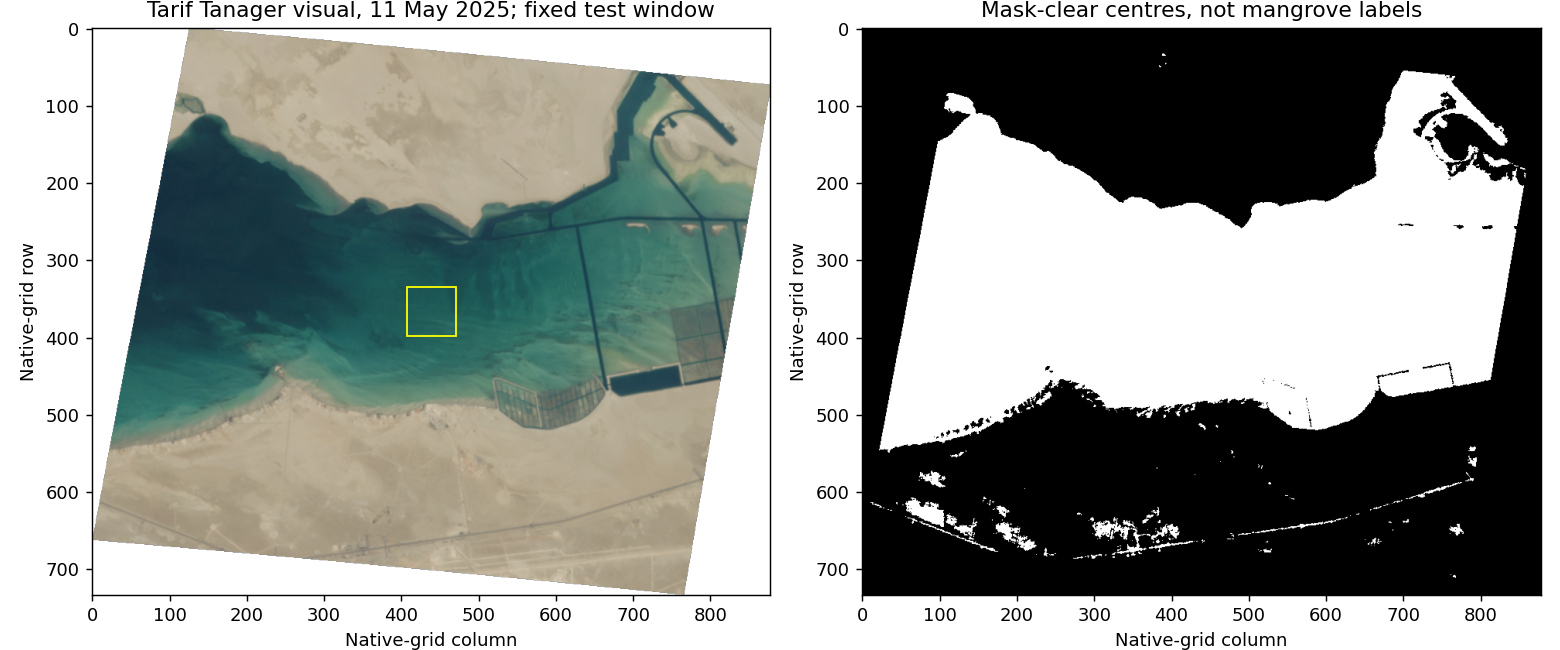

{
  "experiment": "Tarif-2025-source-and-pixel-qualification-v1",
  "started_utc": "2026-10-09T14:18:03.065899+00:00",
  "scene": "20250511_074311_00_4001",
  "date": "2025-05-11T07:43:11Z",
  "scene_cloud_percent": 51,
  "source": "Planet Tanager open STAC; CC BY 4.0",
  "metadata_sha256": "b0ad2085835feb03cd60f768e41c6d1e9377f3aa59a34e6908e9f2e84a898eda",
  "spectral_transfer_limit_bytes": 12582912,
  "heads": {
    "ortho_sr_hdf5": {
      "status": 200,
      "length": "1110606839",
      "ranges": "bytes",
      "etag": "\"e9b3ec690ceb78a08a483d87a18c3809\"",
      "modified": "Sun, 07 Dec 2025 23:07:03 GMT"
    },
    "ortho_beta_udm": {
      "status": 200,
      "length": "30622",
      "ranges": "bytes",
      "etag": "\"2ecae74ae1c75aceed40b01bbf3c1bdf\"",
      "modified": "Sun, 07 Dec 2025 22:55:31 GMT"
    },
    "ortho_visual": {
      "status": 200,
      "length": "875286",
      "ranges": "bytes",
      "etag": "\"370724f35a43ea859f594cd5d4a0ed8a\"",
      "modified": 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# Tarif qualification: new 2025 experiment, never a rerun of Kalba.
import base64, gzip, hashlib, io, json, os, sys, traceback, zipfile
from pathlib import Path
from datetime import datetime, timezone
assert "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG"), "Run science only in Colab"
import requests, h5py, numpy as np
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display
OUT = Path("/content/mangrove_tarif_qualification")
OUT.mkdir(exist_ok=True)
ITEM_RAW = gzip.decompress(base64.b64decode("..."))
assert hashlib.sha256(ITEM_RAW).hexdigest() == "b0ad2085835feb03cd60f768e41c6d1e9377f3aa59a34e6908e9f2e84a898eda"
item = json.loads(ITEM_RAW)
assert item["id"] == "20250511_074311_00_4001"
(OUT / "item.json").write_bytes(ITEM_RAW)
heads = {"ortho_sr_hdf5":{"status":200,"length":"1110606839","ranges":"bytes","etag":"\"e9b3ec690ceb78a08a483d87a18c3809\"","modified":"Sun, 07 Dec 2025 23:07:03 GMT"},"ortho_beta_udm":{"status":200,"length":"30622","ranges":"bytes","etag":"\"2ecae74ae1c75aceed40b01bbf3c1bdf\"","modified":"Sun, 07 Dec 2025 22:55:31 GMT"},"ortho_visual":{"status":200,"length":"875286","ranges":"bytes","etag":"\"370724f35a43ea859f594cd5d4a0ed8a\"","modified":"Sun, 07 Dec 2025 22:55:11 GMT"}}
LIMIT = 12 * 1024**2
BLOCK = 32768
report = {"experiment":"Tarif-2025-source-and-pixel-qualification-v1", "started_utc":datetime.now(timezone.utc).isoformat(),
 "scene":item["id"], "date":item["properties"]["datetime"], "scene_cloud_percent":item["properties"]["cloud_percent"],
 "source":"Planet Tanager open STAC; CC BY 4.0", "metadata_sha256":hashlib.sha256(ITEM_RAW).hexdigest(),
 "spectral_transfer_limit_bytes":LIMIT,"heads":heads,
 "interpretation":"Source/pixel qualification only. Not mangrove truth, independent accuracy, health, drone performance, ecological benefit or hyperspectral incremental value.",
 "frozen_kalba_changed":False, "asset_gets":[], "range_gets":[]}
def get_small(key):
    path = OUT / (key + ".tif")
    if not path.exists():
        expected = int(heads[key]["length"])
        assert expected < 1024**2
        with requests.get(item["assets"][key]["href"], stream=True, timeout=60) as r:
            r.raise_for_status()
            assert int(r.headers["Content-Length"]) == expected
            body = r.raw.read(expected+1)
            assert len(body) == expected
        path.write_bytes(body)
        report["asset_gets"].append({"key":key,"bytes":len(body),"sha256":hashlib.sha256(body).hexdigest()})
    return path
class RangeFile(io.RawIOBase):
    # Disk block cache survives rerunning cells on this runtime; full GET is prohibited.
    def __init__(self, url, size, etag):
        super().__init__(); self.url=url; self.size=size; self.etag=etag; self.pos=0
        self.cache=OUT/("sr_blocks_"+hashlib.sha256((url+etag).encode()).hexdigest()[:16]); self.cache.mkdir(exist_ok=True)
        self.total=sum(p.stat().st_size for p in self.cache.glob("*.bin"))
    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos
    def seek(self, offset, whence=0):
        target=offset if whence==0 else self.pos+offset if whence==1 else self.size+offset
        if target<0: raise ValueError("Negative seek")
        self.pos=target; return target
    def read(self, count=-1):
        end=self.size if count<0 else min(self.size,self.pos+count)
        if end<=self.pos: return b""
        result=[]
        while self.pos<end:
            start=(self.pos//BLOCK)*BLOCK; stop=min(start+BLOCK,self.size)-1
            p=self.cache/f"{start:012d}.bin"
            if p.exists():
                data=p.read_bytes(); assert len(data)==stop-start+1, "Invalid cached block length"
            else:
                expected=stop-start+1
                if self.total+expected>LIMIT: raise RuntimeError("Spectral byte budget reached; do not retry full download")
                with requests.get(self.url,headers={"Range":f"bytes={start}-{stop}","If-Match":self.etag},stream=True,timeout=60) as r:
                    if r.status_code!=206: raise RuntimeError(f"Range rejected ({r.status_code}); body not read")
                    assert r.headers.get("Content-Range")==f"bytes {start}-{stop}/{self.size}"
                    data=r.raw.read(expected+1)
                    assert len(data)==expected
                p.write_bytes(data); self.total+=len(data)
                report["range_gets"].append({"start":start,"end":stop,"bytes":len(data)})
            offset=self.pos-start; take=min(end-self.pos,len(data)-offset)
            assert take>0
            result.append(data[offset:offset+take]); self.pos+=take
        return b"".join(result)
    def readinto(self, buffer):
        data=self.read(len(buffer)); buffer[:len(data)]=data; return len(data)
# Pure format self-check; not scientific validation.
rf_test=RangeFile("unused",100,"unused"); assert rf_test.seek(10)==10
assert rf_test.seek(-2,1)==8 and rf_test.seek(-1,2)==99
rf_test.close()
try:
    visual_path=get_small("ortho_visual"); mask_path=get_small("ortho_beta_udm")
    with Image.open(visual_path) as im:
        rgb=np.asarray(im).copy(); tags=dict(im.tag_v2)
    with Image.open(mask_path) as im: masks=np.asarray(im).copy()
    assert rgb.shape==(733,878,4) and masks.shape==(733,878,3), (rgb.shape,masks.shape)
    # Mask order from actual STAC descriptors: cloud, cirrus, nodata.
    descriptors=item["assets"]["ortho_beta_udm"]["bands"]
    report["mask_descriptors"]=descriptors
    assert ["cloud","cirrus","nodata"] == [("cloud" if "Cloud" in d["name"] else "cirrus" if "Cirrus" in d["name"] else "nodata") for d in descriptors]
    valid=(masks==0).all(axis=2)&(rgb[:,:,3]>0)
    report["native_mask_values"]={descriptors[i]["name"]:np.unique(masks[:,:,i],return_counts=True)[0].tolist() for i in range(3)}
    report["clear_native_centres"]=int(valid.sum()); report["all_native_centres"]=int(valid.size)
    report["clear_fraction_of_rectangular_grid"]=float(valid.mean())
    report["visual_geotiff_tags"]={str(k):tags[k] for k in [33550,33922,34735] if k in tags}
    # Fixed central 64x64 window declared before pixel inspection; no candidate optimization.
    r0,c0=733//2-32,878//2-32; win=(slice(r0,r0+64),slice(c0,c0+64))
    report["window"]={"row":r0,"column":c0,"height":64,"width":64,"selection":"Fixed scene-centre; not tuned to mask/index or labelled as mangrove"}
    report["window_clear_centres"]=int(valid[win].sum())
    fig,ax=plt.subplots(1,2,figsize=(12,5))
    ax[0].imshow(rgb); ax[0].add_patch(plt.Rectangle((c0,r0),64,64,fill=False,color="yellow"))
    ax[0].set_title("Tarif Tanager visual, 11 May 2025; fixed test window")
    ax[1].imshow(valid,cmap="gray",vmin=0,vmax=1); ax[1].set_title("Mask-clear centres, not mangrove labels")
    for a in ax: a.set_xlabel("Native-grid column"); a.set_ylabel("Native-grid row")
    fig.tight_layout(); fig.savefig(OUT/"scene_quality.png",dpi=130); plt.close(fig)
    display(Image.open(OUT/"scene_quality.png"))
    asset=item["assets"]["ortho_sr_hdf5"]
    wave=np.array([b["eo:center_wavelength"] for b in asset["bands"] if b["name"].startswith("surface_reflectance_B")])
    assert len(wave)==426 and np.all(np.diff(wave)>0)
    with RangeFile(asset["href"],int(heads["ortho_sr_hdf5"]["length"]),heads["ortho_sr_hdf5"]["etag"]) as remote:
        with h5py.File(remote,"r") as h:
            group=h["HDFEOS/GRIDS/HYP/Data Fields"]
            d=group["surface_reflectance"]
            report["hdf_datasets"]={k:{"shape":list(v.shape),"dtype":str(v.dtype),"chunks":v.chunks,"compression":v.compression} for k,v in group.items() if isinstance(v,h5py.Dataset)}
            assert d.shape==(426,733,878), d.shape
            # Three independent channels form one reflectance contrast and one red-edge sample; not species/health retrieval.
            idx=[int(np.argmin(abs(wave-w))) for w in [.665,.705,.865]]
            planes=np.stack([d[i,win[0],win[1]] for i in idx])
            # Reject nodata/non-finite/nonpositive sums; reflectance >1 retained in raw crop but excluded from simple contrast.
            usable=valid[win]&np.isfinite(planes).all(axis=0)&(planes>=0).all(axis=0)&(planes<=1).all(axis=0)
            red,edge,nir=planes
            contrast=np.full(red.shape,np.nan)
            accepted=usable&((nir+red)>0)
            contrast[accepted]=(nir[accepted]-red[accepted])/(nir[accepted]+red[accepted])
            report["sampled_channels"]=[{"index":i,"wavelength_um":float(wave[i])} for i in idx]
            report["usable_spectral_centres"]=int(accepted.sum())
            report["contrast_range"]=([float(np.nanmin(contrast)),float(np.nanmax(contrast))] if accepted.any() else None)
            np.savez_compressed(OUT/"fixed_window.npz",reflectance=planes,usable=usable,contrast=contrast,wavelength_um=wave[idx],row=r0,column=c0)
            report["spectral_bytes_in_cache"]=remote.total
    report["status"]="qualified_source_and_crop" if report["usable_spectral_centres"] else "no_usable_fixed_window"
    report["site_switch_gate"]="NOT PASSED: actual species/cover reference and matched independent labels remain absent"
except Exception:
    report["status"]="diagnostic_failure"; report["error"]=traceback.format_exc()
finally:
    report["finished_utc"]=datetime.now(timezone.utc).isoformat()
    (OUT/"qualification.json").write_text(json.dumps(report,indent=2))
    (OUT/"ATTRIBUTION.md").write_text("Planet Tanager scene 20250511_074311_00_4001 (11 May 2025), CC BY 4.0. Source: "+item["links"][0]["href"]+"\nModifications: native-grid visual/mask display and fixed-window channel sampling. No endorsement. Masks are beta quality context, not truth. Team analysis does not validate mangrove identity, health or drone/ecological benefit.\n")
    archive=Path("/content/Mangrove_Pulse_Tarif_Qualification_results.zip")
    with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
        for p in sorted(OUT.rglob("*")):
            if p.is_file(): z.write(p,p.relative_to(OUT))
    print(json.dumps({k:v for k,v in report.items() if k not in ("hdf_datasets","range_gets","mask_descriptors")},indent=2))
    print("RESULT ZIP:",archive.name,"bytes:",archive.stat().st_size,"SHA-256:",hashlib.sha256(archive.read_bytes()).hexdigest())
    from google.colab import files
    files.download(str(archive))
